In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import os
hbond_dir = os.getcwd()
os.chdir('../')
from edautils.plot import ternary_ax, ternary
from edautils.plot import calc_portion, energy_bar_ax
from edautils.plot import kdeplot, kdeplot_norm
from edautils.plot import violin
from edautils.plot import pie
from edautils.plot import plot

os.chdir(hbond_dir)

In [3]:
from matplotlib import font_manager
font_manager.fontManager.addfont("../edautils/fonts/Lato/Lato-Regular.ttf")
font_manager.fontManager.addfont("../edautils/fonts/Helvetica/Helvetica.ttf")

plt.rcParams.update({
    # 'font.size': 12,
    # 'axes.titlesize': 12,
    'font.family': 'sans-serif',
    'font.sans-serif': ['Lato'],
})

COLOR_MAPS = {
    "TOTAL": '#666666',
    "CT": '#b80058',
    "DISP": "#d95f02",
    "ELEC": '#5954d6',
    "POL": '#1b9e77',
    "PAULI": '#ebac23',
    'FRZ': '#a6cee3'
}

df = pd.read_csv('hbond_EDA.csv').iloc[:, 1:]
print('# Total pairs:', len(df))
print('# Repulsive pairs:', len(df.query('TOTAL > 0')))
print('# Attractive pairs:', len(df.query('TOTAL < 0')))

# CLS_DISP
df['DISP'] = np.where(np.isnan(df['DISP'].values), df['CLS_DISP'], df['DISP'])
processed_df = df.query('TOTAL < 0').drop(columns=['resnr_lig', 'restype_lig', 'reschain_lig', 'PREPARATION'])

processed_df["group"] = pd.NA

neutral_mask = (
    (processed_df["charge0"] == 0) &
    (processed_df["charge1"] == 0)
)
charged_mask = (
    ((processed_df["charge0"] == 0) & (processed_df["charge1"] != 0)) |
    ((processed_df["charge0"] != 0) & (processed_df["charge1"] == 0))
)
cc_mask = (
    ((processed_df["charge0"] < 0) & (processed_df["charge1"] > 0)) |
    ((processed_df["charge0"] > 0) & (processed_df["charge1"] < 0))
)

processed_df.loc[neutral_mask, "group"] = "Neutral"
processed_df.loc[charged_mask, "group"] = "Charged"
processed_df.loc[cc_mask, "group"] = "CC"

for x, subdf in processed_df.groupby("group"):
    print(x, subdf.shape[0], subdf['TOTAL'].min())

components = [
    ('TOTAL', 'TOTAL', 'Total'),
    ('MOD_PAULI', 'PAULI', 'Pauli'),
    ('CLS_ELEC', 'CLS_ELEC', 'Electrostatics'),
    ('DISP', 'DISP', 'Dispersion'),
    ('POLARIZATION', 'POL', 'Polarization'),
    ('CHARGE_TRANSFER', 'CT', 'Charge Transfer')
]

groups = ['Neutral', 'Charged', 'CC']

include_all = False
for c, label, pp in components:
    line = f'{pp}'
    if include_all:
        line += f'${np.mean(processed_df[c]):.2f}\\ ({np.median(processed_df[c]):.2f})$'
    for x in groups:
        data = processed_df.query(f'group == "{x}"')[c]
        line += f' & ${np.mean(data):.2f}\\ ({np.median(data):.2f})$'
    line += ' \\\\'
    print(line)

# Total pairs: 4977
# Repulsive pairs: 394
# Attractive pairs: 4583
CC 281 -1514.6779
Charged 1872 -254.7435
Neutral 2430 -109.5813
Total & $-23.85\ (-23.41)$ & $-76.43\ (-73.14)$ & $-506.14\ (-464.87)$ \\
Pauli & $40.93\ (36.12)$ & $54.60\ (42.62)$ & $90.64\ (81.25)$ \\
Electrostatics & $-32.97\ (-31.57)$ & $-70.43\ (-68.06)$ & $-486.08\ (-441.43)$ \\
Dispersion & $-16.69\ (-16.78)$ & $-17.52\ (-16.90)$ & $-22.34\ (-21.71)$ \\
Polarization & $-7.82\ (-6.95)$ & $-30.84\ (-27.58)$ & $-62.98\ (-59.82)$ \\
Charge Transfer & $-7.29\ (-5.99)$ & $-12.24\ (-9.19)$ & $-25.38\ (-23.44)$ \\


# Violin + Bar Plots

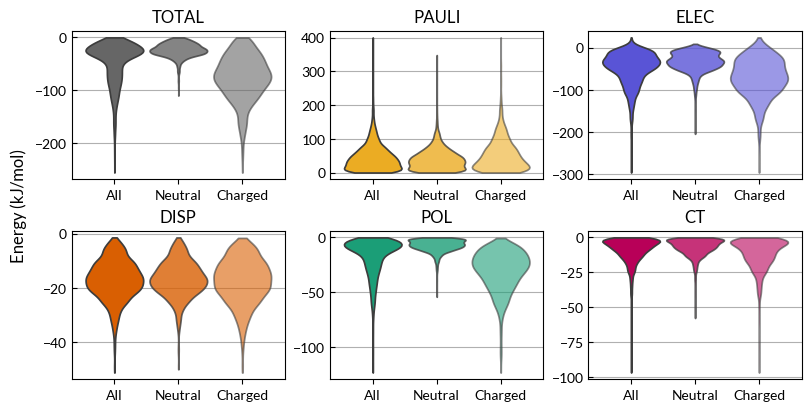

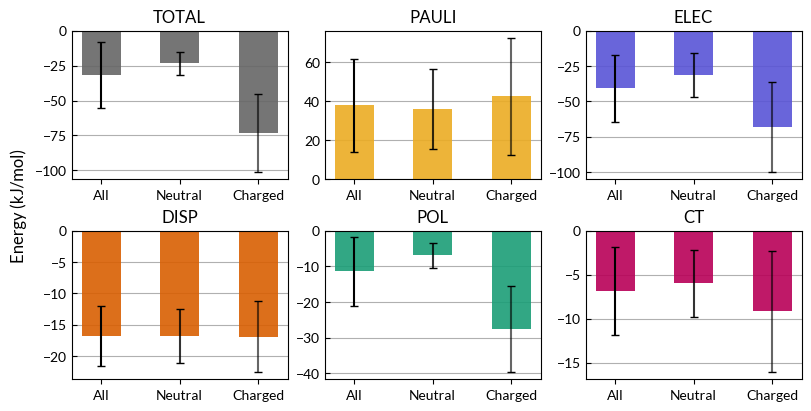

In [7]:
font_manager.fontManager.addfont("../edautils/fonts/Lato/Lato-Regular.ttf")
font_manager.fontManager.addfont("../edautils/fonts/Helvetica/Helvetica.ttf")

processed_df = processed_df[processed_df['group'] != "CC"] 
group_name = 'group'
groups = ['ALL', 'Neutral', 'Charged']
labels = ['All', 'Neutral', 'Charged']


fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='violin')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/violin.png')


fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='bar')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/bar.png')

# Pie Plot

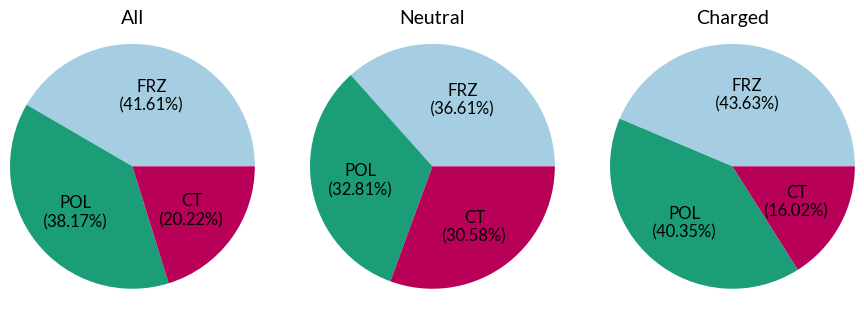

In [8]:
fig, axes = plt.subplots(1, 3, constrained_layout=True, figsize=(9, 3))
pie(axes, group_name, groups, labels, processed_df)
fig.savefig('Visualizations/pie_all.png')

# Ternary Plots

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_8621/1072055476.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


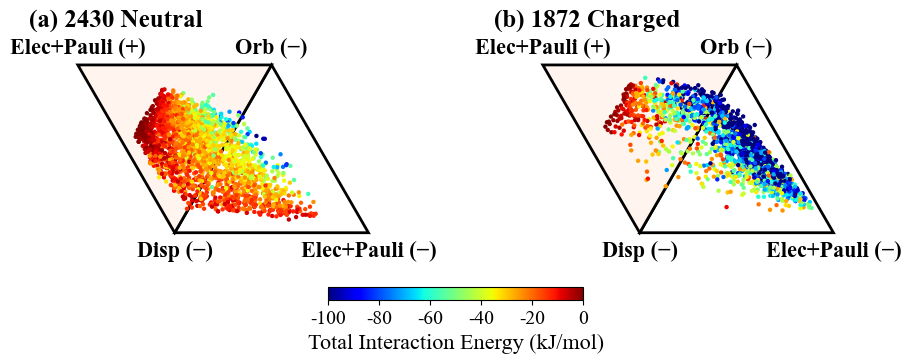

In [19]:
def split_sc(df):
    dfList = []
    dfList.append(df.query('charge0 == 0 & charge1 == 0 & TOTAL < 0'))
    dfList.append(df.query('(charge0 == 0 & charge1 != 0) | (charge0 != 0 & charge1 == 0)'))
    # dfList.append(df.query('(charge0 < 0 & charge1 > 0) | (charge0 > 0 & charge1 < 0)'))
    return dfList

df = pd.read_csv('hbond_EDA.csv')
df = df.query('TOTAL < 0')

dfs = split_sc(df)
labels = ['Neutral', 'Charged']
cmap_range = [-100, 0]
type = 'frz_orb_disp'

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sc = plot('ternary', (labels[0], 'a', type), dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), dfs[1], axes[1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig('Visualizations/ternary1.png')

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_8621/2937225967.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


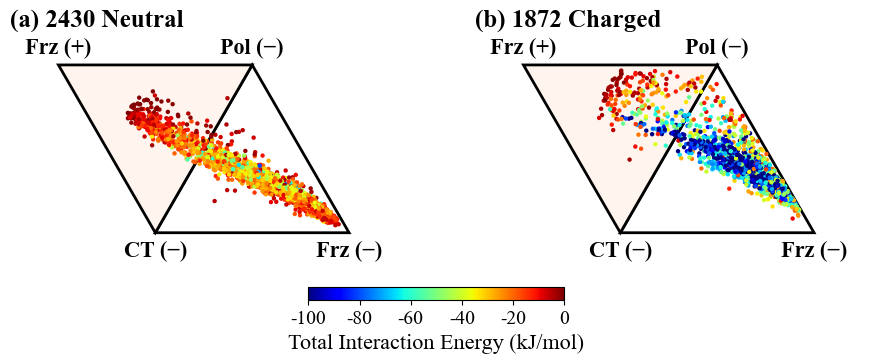

In [20]:
type = 'frz_pol_ct'

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sc = plot('ternary', (labels[0], 'a', type), dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), dfs[1], axes[1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig('Visualizations/ternary2.png')

# Energy Bar Plots

## Bar Plot Ratio type formulation

### ratio1: $R_1 = \frac{\sum_{i} E_{i}^{(t)}}{\sum_{i} E_{i}^{(\text{total})}}$

### ratio2: $R_2 = \sum_{i} \frac{E_{i}^{(t)}}{E_{i}^{(\text{total})}}$

len: list(map(len, dfs))


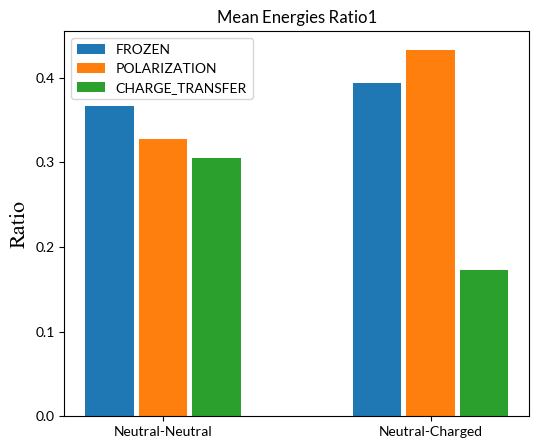

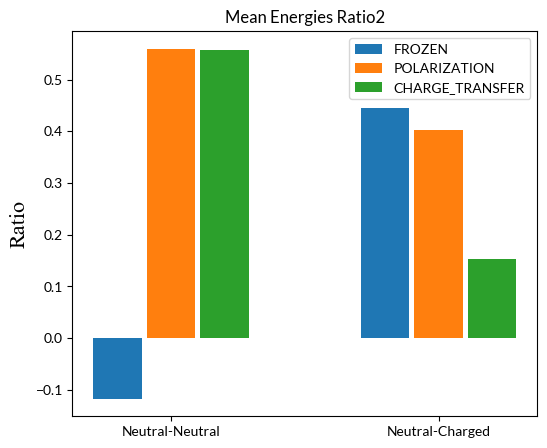

In [13]:
# labels = ['Neutral-Neutral', 'Neutral-Charged', 'Charged-Charged']
labels = ['Neutral-Neutral', 'Neutral-Charged']

def split_sc(df):
    dfList = []
    dfList.append(df.query('charge0 == 0 & charge1 == 0 & TOTAL < 0'))
    dfList.append(df.query('(charge0 == 0 & charge1 != 0) | (charge0 != 0 & charge1 == 0)'))
    # dfList.append(df.query('(charge0 < 0 & charge1 > 0) | (charge0 > 0 & charge1 < 0)'))
    return dfList

items = [
    'FROZEN', 
    # 'CLS_ELEC', 
    # 'MOD_PAULI', 
    # 'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]
dfs = split_sc(df)

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(figsize=(6, 5))
plot('box', (labels, items), dfs, axes, ratio1=True)
axes.set_title('Mean Energies Ratio1')
plt.savefig('Visualizations/box_R1.png')

fig, axes = plt.subplots(figsize=(6, 5))
plot('box', (labels, items), dfs, axes, ratio2=True)
axes.set_title('Mean Energies Ratio2')
plt.savefig('Visualizations/box_R2.png')